# 🧹 2. Carga y limpieza

En este capítulo paso de los archivos crudos de recibos a un **panel limpio negocio × día**, que es la base de todo el análisis que sigue.

Aquí solo aplico **reglas deterministas**: parsear montos, cortar fechas, agregar y completar días según reglas del negocio. Ninguna de estas reglas usa estadísticas calculadas sobre los datos (medias, cuantiles, umbrales), así que no se filtra información del periodo de prueba hacia el entrenamiento. Las decisiones que sí dependen de estadísticas (outliers, escalado, imputación) se toman después de la partición cronológica del capítulo 3, usando solo train.

| Paso | Qué se hace | Sección |
|---|---|---|
| 1 | Leer los CSV y verificar qué fechas trae cada uno | 2.1 |
| 2 | Convertir el monto de texto a número | 2.2 |
| 3 | Unir el catálogo de medios de pago y anonimizar negocios | 2.3 |
| 4 | Excluir el día incompleto (24 sep) | 2.4 |
| 5 | Controles de calidad por fila | 2.5 |
| 6 | Agrupar medios de pago pequeños | 2.6 |
| 7 | Agregar a negocio × día y completar días sin venta | 2.7 – 2.8 |
| 8 | Guardar el panel limpio | 2.9 |

In [1]:
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

SEED = 42
np.random.seed(SEED)

# rutas relativas (los datos viven fuera del repo)
DATA = Path("../../Data")
SALIDA = DATA / "processed"

# paleta del libro
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
AZUL, NARANJA, GRIS = PALETA[0], PALETA[1], "#c9c8c2"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.prop_cycle": plt.cycler(color=PALETA),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8983", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titleweight": "bold", "axes.titlesize": 12,
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
MESES = {7: "jul", 8: "ago", 9: "sep"}

## 📂 2.1 Lectura de los archivos

Los recibos vienen en CSV organizados por año y mes (`Pos_Receipts/2026/<Mes>/<rango>.csv`). Leo todo como texto para controlar yo mismo la conversión de tipos, y guardo de qué archivo sale cada fila.

In [2]:
archivos = sorted(glob.glob(str(DATA / "Pos_Receipts" / "**" / "*.csv"), recursive=True))

partes = []
for f in archivos:
    # utf-8-sig porque los archivos traen BOM al inicio
    d = pd.read_csv(f, dtype=str, encoding="utf-8-sig")
    d["archivo"] = "/".join(Path(f).parts[-2:])  # solo mes/archivo, sin ruta completa
    partes.append(d)
crudo = pd.concat(partes, ignore_index=True)
crudo["Date"] = pd.to_datetime(crudo["Date"])

resumen = crudo.groupby("archivo").agg(
    filas=("Date", "size"),
    desde=("Date", "min"),
    hasta=("Date", "max"),
    dias=("Date", "nunique"),
).sort_values("desde")
resumen["desde"] = resumen["desde"].dt.date
resumen["hasta"] = resumen["hasta"].dt.date
print(f"{len(archivos)} archivos, {len(crudo):,} filas, columnas: {list(crudo.columns[:5])}")
resumen

6 archivos, 143,367 filas, columnas: ['Source', 'Biz.ID', 'Date', 'PM.ID', 'Recibo.Total']


,filas,desde,hasta,dias
archivo,,,,
Julio/1_15.csv,24919,2026-07-01,2026-07-15,15
Julio/16_31.csv,26566,2026-07-16,2026-07-31,16
Agosto/1-15.csv,24790,2026-08-01,2026-08-15,15
Agosto/16-26.csv,26518,2026-08-16,2026-08-31,16
Septiembre/1-15.csv,25383,2026-09-01,2026-09-15,15
Septiembre/16-21.csv,15191,2026-09-16,2026-09-24,9


In [3]:
# reviso que ningún día aparezca en dos archivos y que no falte ningún día
dias_por_archivo = crudo.groupby(crudo["Date"].dt.date)["archivo"].nunique()
todos = pd.date_range(crudo["Date"].min(), crudo["Date"].max()).date
print("días repetidos entre archivos:", (dias_por_archivo > 1).sum())
print("días faltantes en el rango:", len(set(todos) - set(dias_por_archivo.index)))
print("fechas con hora distinta de 00:00:", (crudo["Date"].dt.hour != 0).sum())

días repetidos entre archivos: 0
días faltantes en el rango: 0
fechas con hora distinta de 00:00: 0


### Interpretación

- Son 6 archivos que cubren del 1 de julio al 24 de septiembre sin días repetidos ni faltantes, y todas las fechas vienen a las 00:00 (el dato ya está agregado por día).
- **Los nombres de archivo no coinciden con su contenido**: `Agosto/16-26.csv` trae hasta el 31 y `Septiembre/16-21.csv` trae hasta el 24. Por eso todos los filtros de este libro se hacen **por la columna `Date`**, nunca por el nombre del archivo.

## 💲 2.2 Parseo del monto (`Recibo.Total`)

El monto viene como texto con el formato de moneda del sistema: prefijo `$ `, **coma como separador decimal** y el signo menos delante del `$` en los negativos. Antes de convertir verifico que todas las filas cumplan un único patrón.

In [4]:
monto_txt = crudo["Recibo.Total"]

# patrón esperado: signo opcional, "$ ", dígitos y opcionalmente ",decimales"
patron = r"-?\$ \d+(,\d{1,3})?"
print("filas que NO cumplen el patrón:", (~monto_txt.str.fullmatch(patron)).sum())

con_coma = monto_txt.str.contains(",")
n_dec = monto_txt[con_coma].str.split(",").str[1].str.len()
print(f"filas con coma: {con_coma.sum():,} ({con_coma.mean():.1%})")
print("dígitos después de la coma:", n_dec.value_counts().sort_index().to_dict())
print("negativos:", monto_txt.str.startswith("-").sum())

filas que NO cumplen el patrón: 0
filas con coma: 15,863 (11.1%)
dígitos después de la coma: {1: 6261, 2: 9015, 3: 587}
negativos: 12


In [5]:
# ojo: la coma es decimal, no separador de miles
crudo["monto"] = (monto_txt.str.replace("$", "", regex=False)
                           .str.replace(" ", "", regex=False)
                           .str.replace(",", ".", regex=False)
                           .astype(float))

# qué pasaría si solo se borraran las comas
monto_mal = monto_txt.str.replace(r"[$ ,]", "", regex=True).astype(float)
print("nulos tras convertir:", crudo["monto"].isna().sum())
print(f"total bien parseado: {crudo['monto'].sum():,.0f}")
print(f"total borrando comas: {monto_mal.sum():,.0f}  ({monto_mal.sum() / crudo['monto'].sum():.1f} veces más)")

pd.DataFrame({"texto": monto_txt, "monto": crudo["monto"]})[con_coma | (crudo["monto"] < 0)].drop_duplicates("texto").head(6)

nulos tras convertir: 0
total bien parseado: 892,151,033,287
total borrando comas: 30,974,726,751,125  (34.7 veces más)


,texto,monto
0,"$ 24079207,913","24,079,207.91"
2,"$ 60532854,446","60,532,854.45"
4,"$ 67773622,2","67,773,622.20"
6,"$ 14362660,45","14,362,660.45"
8,"$ 30325557,15","30,325,557.15"
10,"$ 37476323,7","37,476,323.70"


### Interpretación

Todas las filas cumplen el patrón, así que la conversión es segura y no deja nulos. La coma es decimal y no de miles: si fuera de miles siempre habría exactamente 3 dígitos después de ella, y aquí hay 1, 2 o 3. Si solo se borraran las comas, los montos con decimales quedarían multiplicados por 10, 100 o 1000 y el valor total se inflaría varias veces.

```{warning}
La coma en `Recibo.Total` es **separador decimal**. Hay que reemplazarla por punto; si se borra, los montos se inflan por potencias de 10.
```

## 🗂️ 2.3 Tipos, catálogo de medios de pago y anonimización

El catálogo `vw_PaymetMethods.txt` (separado por `;`) trae el nombre y la categoría de cada `PM.ID`. Hay tres categorías: **Contado**, **Crédito propio** (crédito que el negocio le da a sus clientes) y **Crédito empresa** (convenios de crédito corporativo).

Los `Biz.ID` se reemplazan por códigos `N001…N453`, asignados en orden de ID (la numeración se mantiene aunque después se excluya algún negocio). La tabla de equivalencias se guarda solo en la carpeta privada de datos.

In [6]:
cat = pd.read_csv(DATA / "vw_PaymetMethods.txt", sep=";", encoding="utf-8-sig")
cat = cat.rename(columns={"ID": "pm_id", "PaymentMethod": "medio", "Category": "categoria"})

crudo["biz_id"] = crudo["Biz.ID"].astype(int)
crudo["pm_id"] = crudo["PM.ID"].astype(int)

usados = sorted(crudo["pm_id"].unique())
print(f"medios en el catálogo: {len(cat)}, medios usados en los datos: {len(usados)}")
print("medios usados que no están en el catálogo:", set(usados) - set(cat["pm_id"]))
cat.groupby("categoria")["pm_id"].count().rename("medios en catálogo").to_frame()

medios en el catálogo: 26, medios usados en los datos: 19
medios usados que no están en el catálogo: set()


,medios en catálogo
categoria,
Contado,20
Credito Propio,1
Credito Terpel,5


In [7]:
# [IA] anonimizo negocios: N001, N002, ... en orden de ID
ids = sorted(crudo["biz_id"].unique())
mapa_negocios = pd.DataFrame({"biz_id": ids, "negocio": [f"N{i:03d}" for i in range(1, len(ids) + 1)]})
crudo = crudo.merge(mapa_negocios, on="biz_id").merge(cat, on="pm_id", how="left")

df = crudo[["archivo", "Source", "negocio", "Date", "pm_id", "medio", "categoria", "monto"]].rename(
    columns={"Source": "fuente", "Date": "fecha"})
print("negocios:", df["negocio"].nunique())
df.head()

negocios: 453


,archivo,fuente,negocio,fecha,pm_id,medio,categoria,monto
0,Agosto/1-15.csv,TPos Recibos,N001,2026-08-01,1,Efectivo,Contado,"24,079,207.91"
1,Agosto/1-15.csv,TPos Recibos,N001,2026-08-01,10,Bono Fidelizacion,Contado,"70,000.00"
2,Agosto/1-15.csv,TPos Recibos,N001,2026-08-01,11,Rumbo,Credito Terpel,"60,532,854.45"
3,Agosto/1-15.csv,TPos Recibos,N001,2026-08-01,12,Mi Empresa,Credito Terpel,"22,126,707.00"
4,Agosto/1-15.csv,TPos Recibos,N001,2026-08-01,2,Datáfono,Contado,"67,773,622.20"


### Interpretación

Todos los medios de pago que aparecen en los datos existen en el catálogo; se usan 19 de los 26. De aquí en adelante solo se ve el código anonimizado del negocio (`N###`) y el `Biz.ID` original no aparece en ninguna salida.

## ✂️ 2.4 Corte temporal: se excluye el 24 de septiembre

El último archivo se descargó el 25 de septiembre, así que el 24 puede estar incompleto. Lo reviso con el número de negocios que tienen al menos un registro cada día.

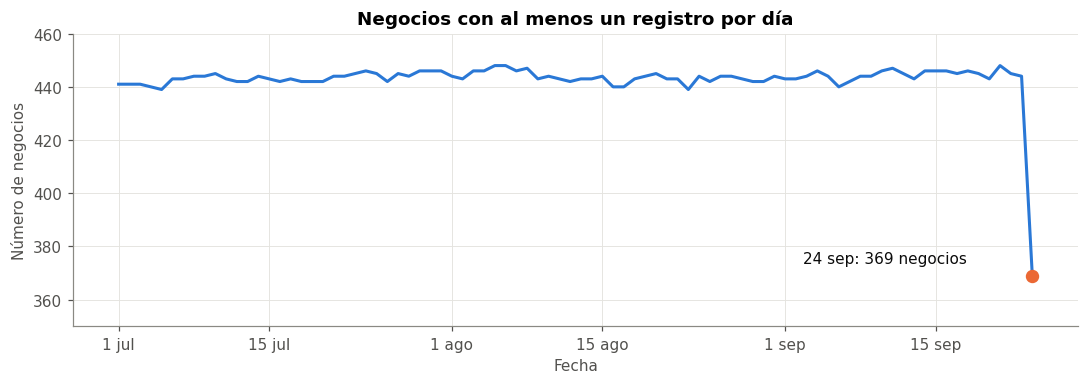

{'min': 439.0, '50%': 444.0, 'max': 448.0}


In [8]:
negocios_dia = df.groupby("fecha")["negocio"].nunique()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(negocios_dia.index, negocios_dia.values, color=AZUL, lw=2)
ultimo = negocios_dia.index[-1]
ax.scatter([ultimo], [negocios_dia.iloc[-1]], color=NARANJA, s=60, zorder=3)
ax.annotate(f"24 sep: {negocios_dia.iloc[-1]} negocios", (ultimo, negocios_dia.iloc[-1]),
            xytext=(-150, 8), textcoords="offset points", color="#0b0b0b")
ax.set_title("Negocios con al menos un registro por día")
ax.set_ylabel("Número de negocios")
ax.set_xlabel("Fecha")
ax.set_ylim(350, 460)
ticks = [f for f in negocios_dia.index if f.day in (1, 15)]
ax.set_xticks(ticks)
ax.set_xticklabels([f"{f.day} {MESES[f.month]}" for f in ticks])
plt.tight_layout()
plt.show()

print(negocios_dia.iloc[:-1].describe()[["min", "50%", "max"]].to_dict())

In [9]:
FECHA_FIN = pd.Timestamp("2026-09-23")
filas_antes = len(df)
df = df[df["fecha"] <= FECHA_FIN].copy()
print(f"filas eliminadas del 24 sep: {filas_antes - len(df):,}; quedan {len(df):,} filas y {df['fecha'].nunique()} días")

filas eliminadas del 24 sep: 1,552; quedan 141,815 filas y 85 días


### Interpretación

Entre el 1 jul y el 23 sep el número de negocios con registro se mantiene muy estable (entre 439 y 448). El 24 cae a 369: el día quedó a medio cargar cuando se exportaron los datos. Si se incluyera, parecería una caída real de la venta ese día y además sería el último dato de la prueba.

```{note}
**Decisión:** el periodo de análisis va del **1 de julio al 23 de septiembre de 2026** (85 días). El 24 se excluye por completo porque su carga está incompleta, no porque sea un valor atípico.
```

## 🔍 2.5 Controles de calidad por fila

Reviso nulos, duplicados, ceros y negativos. También el caso de negocios que aparecen en más de una fuente (sistema de origen).

In [10]:
print("nulos por columna:", df.isna().sum().to_dict())
print("filas idénticas:", df.duplicated().sum())
print("duplicados (fuente, negocio, fecha, medio):", df.duplicated(["fuente", "negocio", "fecha", "pm_id"]).sum())
print("filas cuyo (negocio, fecha, medio) se repite en otra fuente:",
      df.duplicated(["negocio", "fecha", "pm_id"], keep=False).sum())

nulos por columna: {'archivo': 0, 'fuente': 0, 'negocio': 0, 'fecha': 0, 'pm_id': 0, 'medio': 0, 'categoria': 0, 'monto': 0}
filas idénticas: 0
duplicados (fuente, negocio, fecha, medio): 0
filas cuyo (negocio, fecha, medio) se repite en otra fuente: 5012


In [11]:
fuentes = df.groupby("fuente").agg(filas=("monto", "size"), negocios=("negocio", "nunique"), valor=("monto", "sum"))
fuentes["% valor"] = (fuentes["valor"] / fuentes["valor"].sum() * 100).round(2)
fuentes.drop(columns="valor").sort_values("% valor", ascending=False)

,filas,negocios,% valor
fuente,,,
TPos Recibos,85704,218,88.94
Sckuba,40892,156,6.18
Satelite Ventas GNV,11925,76,4.16
Satelite Ventas LIQ,524,2,0.67
Satelite Ventas Canastilla,2532,37,0.04
Manual,238,2,0.01


In [12]:
# [IA] negocios que aparecen en más de una fuente y qué combinación usan
fuentes_neg = df.groupby("negocio")["fuente"].agg(lambda s: " + ".join(sorted(s.unique())))
multi = fuentes_neg[df.groupby("negocio")["fuente"].nunique() > 1]
print(f"negocios en 2 fuentes: {len(multi)}")
multi.value_counts().rename("negocios").to_frame()

negocios en 2 fuentes: 38


,negocios
fuente,
Satelite Ventas Canastilla + Satelite Ventas GNV,37
Sckuba + TPos Recibos,1


Hay 37 negocios con **Satélite Canastilla + Satélite GNV**. Son dos líneas de venta distintas del mismo negocio, así que se suman.

El negocio que combina **Sckuba + TPos** se ve distinto. Reviso su venta semanal por fuente:

In [13]:
neg_pos = multi[multi.str.contains("TPos")].index[0]
semanal = (df[df["negocio"] == neg_pos]
           .groupby([pd.Grouper(key="fecha", freq="W-SUN"), "fuente"])["monto"].sum()
           .unstack() / 1e6)
semanal.index = semanal.index.date
print(neg_pos, "- venta semanal por fuente (millones)")
semanal.round(1)

N093 - venta semanal por fuente (millones)


fuente,Sckuba,TPos Recibos
2026-07-05,11.90,NaN
2026-07-12,18.30,NaN
2026-07-19,17.20,NaN
2026-07-26,16.60,NaN
2026-08-02,16.30,NaN
2026-08-09,14.00,NaN
2026-08-16,18.10,NaN
2026-08-23,15.50,NaN
2026-08-30,16.40,NaN
2026-09-06,16.00,453.00


Desde el 1 de septiembre este negocio empezó a reportar también por TPos, por un cambio de sistema POS. Si fuera un simple reemplazo, Sckuba debería bajar cuando aparece TPos. Pero Sckuba sigue en su nivel de siempre (~16 M/semana) y TPos agrega **unas 30 veces más** (~490 M/semana). No es coherente con la historia del negocio.

```{warning}
**Decisión (área de negocio):** el negocio se **elimina** del análisis por **inconsistencias en el cambio de su sistema POS**. Sus datos de septiembre no son comparables con los de julio y agosto, y el salto caería justo en el periodo de prueba, donde distorsionaría las métricas.
```

In [14]:
# elimino el negocio con el cambio de POS inconsistente
NEGOCIOS_EXCLUIDOS = [neg_pos]
filas_antes = len(df)
df = df[~df["negocio"].isin(NEGOCIOS_EXCLUIDOS)].copy()
print(f"excluidos: {NEGOCIOS_EXCLUIDOS} -> {filas_antes - len(df)} filas; quedan {df['negocio'].nunique()} negocios")

excluidos: ['N093'] -> 398 filas; quedan 452 negocios


In [15]:
ceros = df[df["monto"] == 0]
print(f"filas con monto 0: {len(ceros)}")
ceros.groupby(["fuente", "pm_id", "medio"]).size().rename("filas").to_frame()

filas con monto 0: 494


filas
fuente       pm_id medio                
TPos Recibos 4     Bonos Privados      1
             5     Gopass              1
             6     App Terpel          1
             15    Consumo Propio    491

In [16]:
neg = df[df["monto"] < 0].sort_values("monto")
print(f"filas negativas: {len(neg)}, suman {neg['monto'].sum():,.0f}")
neg[["fecha", "fuente", "negocio", "medio", "monto"]]

filas negativas: 12, suman -117,323,334


,fecha,fuente,negocio,medio,monto
88644,2026-09-01,TPos Recibos,N347,Efectivo,"-84,045,650.00"
41203,2026-07-06,TPos Recibos,N237,Efectivo,"-22,602,172.00"
4506,2026-08-31,TPos Recibos,N012,Efectivo,"-9,123,487.00"
4604,2026-07-31,TPos Recibos,N012,Efectivo,"-542,091.00"
73862,2026-08-21,TPos Recibos,N312,Efectivo,"-483,428.00"
74304,2026-09-17,TPos Recibos,N312,Efectivo,"-410,188.00"
70534,2026-07-10,TPos Recibos,N304,Bonos Privados,"-37,722.00"
79525,2026-09-22,Satelite Ventas GNV,N325,Efectivo,"-29,999.00"
73884,2026-08-24,TPos Recibos,N312,Efectivo,"-27,425.00"
52196,2026-09-10,Satelite Ventas GNV,N260,Efectivo,"-20,949.00"


### Interpretación

| Control | Resultado | Decisión |
|---|---|---|
| Nulos | 0 en todas las columnas | Nada que imputar a nivel de fila |
| Duplicados dentro de una fuente | 0 | — |
| (negocio, día, medio) repetido entre fuentes | Sí, en negocios con 2 fuentes | **Se suman**: son dos líneas de venta distintas (Canastilla + GNV) |
| Negocio con cambio de POS inconsistente | 1 negocio (Sckuba + TPos) | **Se elimina** |
| Montos en 0 | Casi todos en *Consumo Propio* (TPos) | Se conservan: registran consumo interno sin cobro |
| Negativos | 12 filas (reversos) | **Se conservan**: un reverso anula una venta real y se registra tal como ocurre |

La fuente TPos concentra casi el 89 % del valor. Los negativos son reversos de cobros: la mayoría son pequeños, pero hay algunos de decenas de millones, lo bastante grandes para dejar un negocio-día con venta total negativa (lo veo en 2.8).

```{note}
**Decisión (área de negocio):** los reversos son movimientos reales y el pronóstico debe incluirlos tal como ocurren. No se borran ni se recortan aquí. Como `log1p` no está definido para valores ≤ −1, su tratamiento para la transformación log se decide en el preprocesamiento (cap. 7) con reglas ajustadas solo en train.
```

## 💳 2.6 Agrupación de medios de pago

Los medios de pago solo entrarán al modelo como **rezagos** (la venta de ayer por medio), y tener 19 columnas casi vacías añade ruido sin aportar señal. Por eso conservo por separado los medios que pesan al menos 1 % del valor y agrupo el resto en *otros*.

El peso de cada medio lo calculo **solo con julio y agosto**. Así la decisión usa únicamente datos que quedan dentro de train con la partición propuesta para el capítulo 3 (prueba = últimas 3 semanas de septiembre), y no mira el periodo de prueba. Si en el capítulo 3 el corte quedara antes del 31 de agosto, este cálculo se repetiría.

In [17]:
# [IA] participación de cada medio usando solo jul-ago (queda dentro de train)
jul_ago = df[df["fecha"] < "2026-09-01"]
peso = (jul_ago.groupby(["pm_id", "medio", "categoria"])["monto"].sum()
        .sort_values(ascending=False).reset_index())
peso["% valor"] = peso["monto"] / peso["monto"].sum() * 100
peso["% acumulado"] = peso["% valor"].cumsum()
peso["negocios que lo usan"] = peso["pm_id"].map(jul_ago.groupby("pm_id")["negocio"].nunique())
peso.drop(columns="monto").round(2)

,pm_id,medio,categoria,% valor,% acumulado,negocios que lo usan
0,1,Efectivo,Contado,48.72,48.72,447
1,2,Datáfono,Contado,35.76,84.49,368
2,11,Rumbo,Credito Terpel,9.98,94.47,144
3,12,Mi Empresa,Credito Terpel,2.89,97.36,145
4,9,Credito Clientes,Credito Propio,1.40,98.76,126
5,10,Bono Fidelizacion,Contado,0.61,99.37,290
6,23,Rappi Delivery,Contado,0.20,99.57,52
7,5,Gopass,Contado,0.13,99.70,89
8,6,App Terpel,Contado,0.11,99.81,222
9,7,Kushki,Contado,0.08,99.89,2


In [18]:
MEDIOS_SEPARADOS = {1: "efectivo", 2: "datafono", 11: "rumbo", 12: "mi_empresa", 9: "credito_clientes"}

# verifico que coincida con la regla del 1 %
regla = set(peso.loc[peso["% valor"] >= 1, "pm_id"])
print("regla >= 1 % en jul-ago:", sorted(regla), "| coincide:", regla == set(MEDIOS_SEPARADOS))

df["grupo_pm"] = df["pm_id"].map(MEDIOS_SEPARADOS).fillna("otros")
df.groupby("grupo_pm")["monto"].sum().div(df["monto"].sum()).mul(100).round(2).sort_values(ascending=False).rename("% valor (todo el periodo)").to_frame()

regla >= 1 % en jul-ago: [1, 2, 9, 11, 12] | coincide: True


,% valor (todo el periodo)
grupo_pm,
efectivo,48.58
datafono,35.68
rumbo,10.11
mi_empresa,2.94
credito_clientes,1.43
otros,1.26


### Interpretación

Cinco medios concentran cerca del 99 % del valor: **Efectivo** y **Datáfono** (contado), **Rumbo** y **Mi Empresa** (crédito empresa) y **Crédito clientes** (crédito propio). Los otros 14 pesan menos del 1 % cada uno y se agrupan en `otros`. Algunos los usan muchos negocios (por ejemplo, Bono Fidelización), pero mueven muy poco dinero, así que como rezago individual aportarían casi nada. Con el periodo completo la participación casi no cambia, lo que indica que la agrupación es estable.

Los medios de crédito (Rumbo, Mi Empresa, Crédito clientes) se tratan igual que cualquier otro medio de pago: el objetivo es la **venta total diaria**, sin importar cuándo entra el dinero a caja. También guardo el total por **categoría del catálogo** (contado, crédito propio, crédito empresa), pero solo como información descriptiva para el EDA.

## 🧮 2.7 Agregación a negocio × día

Sumo sobre fuentes y medios para tener una fila por negocio y día, con una columna por grupo de medios, el total por categoría y la venta total. Las filas de fuentes distintas se suman (ver 2.5).

In [19]:
# [IA] pivot: una fila por negocio-día, columnas por grupo de medio y por categoría
por_medio = df.pivot_table(index=["negocio", "fecha"], columns="grupo_pm", values="monto",
                           aggfunc="sum", fill_value=0)
por_medio = por_medio[list(MEDIOS_SEPARADOS.values()) + ["otros"]].add_prefix("pm_")

cat_col = {"Contado": "cat_contado", "Credito Propio": "cat_credito_propio"}
df["grupo_cat"] = df["categoria"].map(cat_col).fillna("cat_credito_empresa")
por_cat = df.pivot_table(index=["negocio", "fecha"], columns="grupo_cat", values="monto",
                         aggfunc="sum", fill_value=0)

panel = por_medio.join(por_cat)
panel["venta_total"] = panel[[c for c in panel if c.startswith("pm_")]].sum(axis=1)
panel["n_fuentes"] = df.groupby(["negocio", "fecha"])["fuente"].nunique()
panel = panel.reset_index()

# chequeo: no se pierde plata al agregar
print("diferencia vs. filas crudas:", round(panel["venta_total"].sum() - df["monto"].sum(), 2))
print("diferencia medios vs. categorías:", round((panel.filter(like="pm_").sum(axis=1) - panel.filter(like="cat_").sum(axis=1)).abs().max(), 2))
print(f"filas negocio-día observadas: {len(panel):,}")

diferencia vs. filas crudas: 0.0
diferencia medios vs. categorías: 0.0
filas negocio-día observadas: 37,631


## 📅 2.8 Días sin registro: completar el panel

No todos los negocios tienen fila todos los días. Según el área de negocio, un día sin fila significa cosas distintas según dónde cae:

| Caso | Significado | Tratamiento |
|---|---|---|
| Día sin fila **entre** el primer y el último registro del negocio | El negocio no vendió ese día | Se agrega la fila con **venta 0** y marca `sin_registro = 1` |
| Días **antes** del primer registro | El negocio aún no se había recibido de franquicia | No se agregan filas (no existía en la operación) |
| Días **después** del último registro | El negocio se entregó en franquicia | No se agregan filas |

Es una regla del negocio, no una estadística de los datos, así que no genera fuga.

In [20]:
# [IA] rango activo de cada negocio y reindexado diario dentro de ese rango
rango = panel.groupby("negocio")["fecha"].agg(inicio="min", fin="max")
indice = pd.MultiIndex.from_tuples(
    [(n, f) for n, r in rango.iterrows() for f in pd.date_range(r["inicio"], r["fin"])],
    names=["negocio", "fecha"])

completo = panel.set_index(["negocio", "fecha"]).reindex(indice)
completo["sin_registro"] = completo["venta_total"].isna().astype(int)
completo = completo.fillna(0).reset_index()
completo["n_fuentes"] = completo["n_fuentes"].astype(int)

INICIO = df["fecha"].min()
print(f"filas agregadas como día sin venta: {completo['sin_registro'].sum()}")
print(f"negocios con huecos internos: {completo.groupby('negocio')['sin_registro'].max().sum()}")
print(f"negocios con los 85 días: {(completo.groupby('negocio').size() == 85).sum()}")
print(f"entran después del 1 jul: {(rango['inicio'] > INICIO).sum()}  |  salen antes del 23 sep: {(rango['fin'] < FECHA_FIN).sum()}")

filas agregadas como día sin venta: 197
negocios con huecos internos: 44
negocios con los 85 días: 431
entran después del 1 jul: 12  |  salen antes del 23 sep: 9


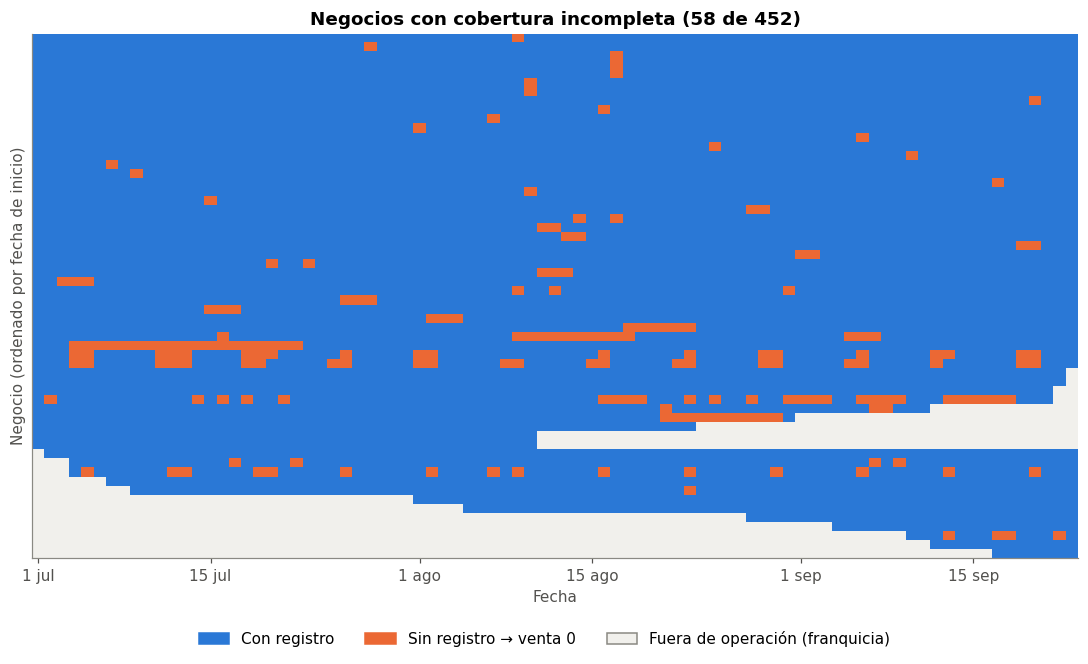

In [21]:
# [IA] mapa de cobertura, solo negocios con cobertura incompleta (los demás son 85 días seguidos)
fechas = pd.date_range(INICIO, FECHA_FIN)
n_huecos = completo.groupby("negocio")["sin_registro"].sum()
incompletos = rango[(rango["inicio"] > INICIO) | (rango["fin"] < FECHA_FIN) | (n_huecos > 0)]
incompletos = incompletos.assign(huecos=n_huecos).sort_values(["inicio", "fin", "huecos"], ascending=[True, False, True])

estado = (completo.assign(v=np.where(completo["sin_registro"] == 1, 2, 1))
          .pivot(index="negocio", columns="fecha", values="v")
          .reindex(index=incompletos.index, columns=fechas).fillna(0))

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(estado.values, aspect="auto", interpolation="nearest",
          cmap=ListedColormap(["#f1f0ec", AZUL, NARANJA]), vmin=0, vmax=2)
ticks = [i for i, f in enumerate(fechas) if f.day in (1, 15)]
ax.set_xticks(ticks)
ax.set_xticklabels([f"{fechas[i].day} {MESES[fechas[i].month]}" for i in ticks])
ax.set_yticks([])
ax.grid(False)
ax.set_title(f"Negocios con cobertura incompleta ({len(estado)} de {len(rango)})")
ax.set_xlabel("Fecha")
ax.set_ylabel("Negocio (ordenado por fecha de inicio)")
fig.legend(handles=[Patch(color=AZUL, label="Con registro"),
                    Patch(color=NARANJA, label="Sin registro → venta 0"),
                    Patch(facecolor="#f1f0ec", edgecolor="#8a8983", label="Fuera de operación (franquicia)")],
           loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

In [22]:
# cómo se reparten los huecos entre negocios
huecos = completo.groupby("negocio")["sin_registro"].sum()
huecos = huecos[huecos > 0]
print("huecos por negocio (solo los que tienen):", huecos.describe()[["count", "50%", "max"]].to_dict())
print("negocios con más de 10 días sin venta:", (huecos > 10).sum())

activos = rango.assign(dias=(rango["fin"] - rango["inicio"]).dt.days + 1)
print("negocios con menos de 30 días de historia:", (activos["dias"] < 30).sum())
print("negocio-días con venta total <= 0 (sin contar los agregados):",
      ((completo["venta_total"] <= 0) & (completo["sin_registro"] == 0)).sum())

huecos por negocio (solo los que tienen): {'count': 44.0, '50%': 2.0, 'max': 26.0}
negocios con más de 10 días sin venta: 6
negocios con menos de 30 días de historia: 5
negocio-días con venta total <= 0 (sin contar los agregados): 2


### Interpretación

- La gran mayoría de los negocios (394 de 452) opera los 85 días sin ningún hueco. La figura muestra solo los que no.
- Los huecos internos (naranja) son pocos y se concentran en unos cuantos negocios: casi siempre 1 o 2 días sueltos, aunque hay negocios con varias semanas sin venta. Ahora son filas con venta 0 y marca `sin_registro`, para que el modelo pueda distinguir "no vendió" de "vendió poco".
- Algunos negocios entran tarde (recibidos de franquicia) y otros salen antes (entregados). Varios de los que entran en agosto y septiembre tienen menos de 30 días de historia, lo que limita los rezagos largos que se pueden calcular para ellos.
- Hay negocio-días con venta total ≤ 0 aunque sí tienen registro, por el efecto de los reversos grandes (2.5).

```{warning}
**Limitaciones que se arrastran:** (1) los días con venta 0 y los negativos impiden aplicar `log1p` directamente, y se resuelve en el capítulo 7. (2) Los negocios con historia corta tendrán rezagos faltantes al inicio de su serie. (3) El 0 de un día sin fila está confirmado por el negocio, pero no se puede distinguir de un día en que el sistema no reportó.
```

## 💾 2.9 Panel limpio y guardado

El panel se guarda en `Data/processed/`, fuera del repositorio. La tabla de equivalencias de negocios también queda ahí y **nunca se publica**.

In [23]:
SALIDA.mkdir(exist_ok=True)
completo = completo.sort_values(["negocio", "fecha"]).reset_index(drop=True)
# redondeo a centavos (la suma deja ruido de punto flotante)
montos = [c for c in completo if c.startswith(("pm_", "cat_", "venta"))]
completo[montos] = completo[montos].round(2)
completo.to_csv(SALIDA / "panel_negocio_dia.csv", index=False)
mapa_negocios.to_csv(SALIDA / "mapa_negocios_PRIVADO.csv", index=False)

print(f"panel: {completo.shape[0]:,} filas x {completo.shape[1]} columnas")
print(f"negocios: {completo['negocio'].nunique()}, días: {completo['fecha'].nunique()}, "
      f"del {completo['fecha'].min().date()} al {completo['fecha'].max().date()}")
completo.dtypes.rename("tipo").to_frame().T

panel: 37,828 filas x 14 columnas
negocios: 452, días: 85, del 2026-07-01 al 2026-09-23


,negocio,fecha,pm_efectivo,pm_datafono,pm_rumbo,pm_mi_empresa,pm_credito_clientes,pm_otros,cat_contado,cat_credito_empresa,cat_credito_propio,venta_total,n_fuentes,sin_registro
tipo,object,datetime64[ns],float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64


In [24]:
# vistazo a un negocio de ejemplo (montos en millones)
ejemplo = completo[completo["negocio"] == "N001"].head(7).set_index("fecha").drop(columns="negocio")
montos = [c for c in ejemplo if c.startswith(("pm_", "cat_", "venta"))]
ejemplo[montos] = (ejemplo[montos] / 1e6).round(2)
ejemplo

,pm_efectivo,pm_datafono,pm_rumbo,pm_mi_empresa,pm_credito_clientes,pm_otros,cat_contado,cat_credito_empresa,cat_credito_propio,venta_total,n_fuentes,sin_registro
fecha,,,,,,,,,,,,
2026-07-01,18.37,55.37,66.41,24.84,0.37,0.66,74.40,91.25,0.37,166.01,1,0
2026-07-02,26.63,64.78,76.04,28.07,0.60,0.15,91.42,104.25,0.60,196.27,1,0
2026-07-03,23.32,63.14,65.48,23.04,0.10,0.57,87.02,88.52,0.10,175.64,1,0
2026-07-04,23.84,60.83,39.43,24.00,0.00,0.67,85.33,63.43,0.00,148.76,1,0
2026-07-05,25.99,45.75,34.42,24.06,0.23,0.13,71.88,58.48,0.23,130.59,1,0
2026-07-06,24.41,39.79,43.62,18.00,0.00,0.88,65.08,61.62,0.00,126.70,1,0
2026-07-07,17.99,55.85,49.64,17.18,0.45,0.29,74.12,66.82,0.45,141.39,1,0


## ✅ Resumen del capítulo

| Aspecto | Resultado |
|---|---|
| Filas crudas (1 jul – 24 sep) | 143 367 |
| Periodo de análisis | 1 jul – 23 sep 2026 (85 días) |
| Unidad de observación | negocio × día |
| Negocios (entidades independientes) | 452 (453 originales, 1 excluido) |
| Filas del panel | 37 828 (37 631 observadas + 197 días sin venta) |
| Columnas | 6 grupos de medio (`pm_*`), 3 categorías (`cat_*`), `venta_total`, `n_fuentes`, `sin_registro` |

### Decisiones y el hallazgo que las motiva

| Decisión | Hallazgo | Sección |
|---|---|---|
| Reemplazar la coma por punto en el monto | 11 % de las filas trae decimales con coma; borrarla infla los montos | 2.2 |
| Filtrar por `Date` y no por nombre de archivo | Los nombres de archivo no coinciden con sus fechas | 2.1 |
| Excluir el 24 sep | Solo 369 negocios ese día, contra 439–448 los demás | 2.4 |
| Sumar entre fuentes | Los repetidos entre fuentes son líneas de venta distintas, no duplicados | 2.5 |
| Eliminar el negocio con cambio de POS | Su venta se multiplica ~30 veces desde sep sin que baje el sistema anterior | 2.5 |
| Conservar reversos y ceros | Son movimientos reales (decisión del negocio) | 2.5 |
| Agrupar 14 medios en `otros` | Pesan < 1 % cada uno (calculado con jul–ago) | 2.6 |
| Días sin fila dentro del rango = venta 0 | Regla del negocio: no hubo venta | 2.8 |
| No crear filas fuera del rango activo | Entradas y salidas son cambios de franquicia | 2.8 |

```{tip}
Ninguna de estas reglas usa medias, cuantiles ni umbrales calculados con los datos. La única decisión que depende de los datos (la agrupación de medios) se tomó con julio y agosto, que quedan dentro de train. Lo demás se ajusta después de la partición del capítulo 3.
```